# Experimental false-positive pruning for AML alerts

This notebook is a **research-only second stage**. The deployed entity-v3 policy first creates an alert queue; this experiment then learns which predicted-positive alerts are likely false positives (FPs). It never changes the production bundle or threshold.

Protocol: fit on the chronological **tune** alert queue, select on **calibration**, and report once on **test**. K-Means first discovers groups within the predicted-positive alert queue without using FP labels. Cluster membership and distances are then added as features to a supervised XGBoost FP ranker. K-Means is also retained as a low-data fallback. Before/after tables always disclose the precision gain and recall/true-positive cost at equal removal budgets.

In [16]:
from pathlib import Path
import ast, hashlib, json, os, subprocess, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.metrics import average_precision_score, roc_auc_score, silhouette_score
from sklearn.preprocessing import StandardScaler
import xgboost as xgb

ROOT = Path(os.environ.get('AML_EXPERIMENT_ROOT', Path.cwd())).resolve()
while ROOT != ROOT.parent and not (ROOT / 'aml_app').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'aml_app').is_dir():
    raise RuntimeError('Run this notebook from the AML_production repository.')
sys.path.insert(0, str(ROOT))

import aml_app.artifacts as artifact_validation
from aml_app.artifacts import ArtifactError
from aml_app.pipeline import read_transactions
from aml_app.service import AMLScorer
from training.train import temporal_splits

DATA_PATH = ROOT / 'data/raw/HI-Small_Trans.csv'
ARTIFACT_DIR = ROOT / 'production_artifacts'
OUTPUT_DIR = ROOT / 'artifacts/fp_pruning_experiment'
SEED = 42
MIN_ALERTS_PER_CLASS = 30
BUDGETS = [0.05, 0.10, 0.20, 0.30, 0.40, 0.50]
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print({'data': str(DATA_PATH), 'bundle': str(ARTIFACT_DIR), 'output': str(OUTPUT_DIR)})

{'data': '/home/malnaser/EN_Workspace/DEVELOPMENT/_playground/DS-Internship-Summer-2026/AML_production/data/raw/HI-Small_Trans.csv', 'bundle': '/home/malnaser/EN_Workspace/DEVELOPMENT/_playground/DS-Internship-Summer-2026/AML_production/production_artifacts', 'output': '/home/malnaser/EN_Workspace/DEVELOPMENT/_playground/DS-Internship-Summer-2026/AML_production/artifacts/fp_pruning_experiment'}


## 1. Reproduce the deployed alert queues

The normal artifact validator remains enabled. This working tree adds documentation to `pipeline.py`, so its byte checksum differs from the trained bundle even though its executable AST is unchanged. The helper below permits that narrow case only: it verifies that the bundle matches the Git `HEAD` source byte-for-byte, removes docstrings and the known unused `io` import from both ASTs, and requires the remaining executable structures to be identical. Any real feature-logic change still stops execution. All model-file checksum checks remain active, and nothing in production is modified. Labels are joined only after scoring and are never passed into the production feature builder.

In [17]:
def _logic_ast(source):
    class DocumentationCleaner(ast.NodeTransformer):
        def generic_visit(self, node):
            node = super().generic_visit(node)
            body = getattr(node, 'body', None)
            if isinstance(body, list) and body and isinstance(body[0], ast.Expr) and isinstance(body[0].value, ast.Constant) and isinstance(body[0].value.value, str):
                node.body = body[1:]
            return node
        def visit_Import(self, node):
            node.names = [alias for alias in node.names if alias.name != 'io']
            return node if node.names else None
    return ast.dump(DocumentationCleaner().visit(ast.parse(source)), include_attributes=False)

def load_research_scorer():
    try:
        return AMLScorer(ARTIFACT_DIR), 'exact source checksum match'
    except ArtifactError as exc:
        if str(exc) != 'Feature implementation differs from the trained release.':
            raise
        manifest = json.loads((ARTIFACT_DIR / 'manifest.json').read_text())
        expected_hash = manifest['feature_source_sha256']
        git_root = Path(subprocess.check_output(['git', 'rev-parse', '--show-toplevel'], cwd=ROOT, text=True).strip())
        tracked_path = (ROOT.relative_to(git_root) / 'aml_app/pipeline.py').as_posix()
        trained_source = subprocess.check_output(['git', 'show', f'HEAD:{tracked_path}'], cwd=ROOT).decode()
        current_source = (ROOT / 'aml_app/pipeline.py').read_text()
        if hashlib.sha256(trained_source.encode()).hexdigest() != expected_hash:
            raise RuntimeError('The bundle does not match the committed pipeline source; use its matching release.') from exc
        if _logic_ast(current_source) != _logic_ast(trained_source):
            raise RuntimeError('Executable feature logic changed; retrain instead of bypassing validation.') from exc
        original_source_hash = artifact_validation.source_hash
        artifact_validation.source_hash = lambda: expected_hash
        try:
            scorer = AMLScorer(ARTIFACT_DIR)  # all remaining bundle checks still run
        finally:
            artifact_validation.source_hash = original_source_hash
        return scorer, 'documentation-only source difference verified against Git HEAD'

scorer, compatibility = load_research_scorer()
print(f'Artifact compatibility: {compatibility}')
raw = read_transactions(DATA_PATH)
if 'Is Laundering' not in raw or not raw['Is Laundering'].isin([0, 1]).all():
    raise ValueError('A binary Is Laundering column is required for this experiment.')
timestamps = pd.to_datetime(raw['Timestamp'], utc=True, format='mixed').to_numpy()
# Training normalizes into chronological order with source order as the tie-break.
order = np.argsort(timestamps, kind='stable')
raw = raw.iloc[order].reset_index(drop=True)
timestamps = timestamps[order]
splits = temporal_splits(timestamps)
print(f'{len(raw):,} rows; model={scorer.version}; threshold={scorer.policy["threshold"]:.6f}')
{name: (selection.start, selection.stop) for name, selection in splits.items()}

Artifact compatibility: documentation-only source difference verified against Git HEAD
5,078,345 rows; model=entity-v3; threshold=0.031146


{'train': (0, 3046861),
 'tune': (3046861, 3554649),
 'calibration': (3554649, 4062463),
 'test': (4062463, 5078345)}

In [18]:
def make_alert_dataset(name):
    part = raw.iloc[splits[name]].reset_index(drop=True)
    labels = part['Is Laundering'].to_numpy(dtype='int8')
    scored, matrix = scorer.score_with_matrix(part)
    alert_rows = scored.loc[scored.alert].copy()
    row_ids = alert_rows['_input_order'].to_numpy(dtype='int64')
    alert_matrix = matrix.loc[row_ids].reset_index(drop=True)
    meta = pd.DataFrame({
        'model_a_score': alert_rows.model_a_score.to_numpy(),
        'model_b_score': alert_rows.model_b_score.to_numpy(),
        'baseline_b_score': alert_rows.baseline_b_score.to_numpy(),
        'risk_score': alert_rows.risk_score.to_numpy(),
        'score_margin': alert_rows.risk_score.to_numpy() - scorer.policy['threshold'],
        'model_disagreement': abs(alert_rows.model_a_score.to_numpy() - alert_rows.model_b_score.to_numpy()),
    })
    candidates = pd.concat([meta, alert_matrix], axis=1)
    # Remove constant columns on tune later; no identifiers, timestamps, or labels enter X.
    return {'X': candidates, 'y_fp': 1 - labels[row_ids], 'y': labels, 'alerts': len(row_ids)}

queues = {name: make_alert_dataset(name) for name in ['tune', 'calibration', 'test']}
del raw
summary = pd.DataFrame([{
    'split': name, 'rows': len(q['y']), 'alerts': q['alerts'],
    'true_positives_in_queue': int((q['y_fp'] == 0).sum()),
    'false_positives_in_queue': int(q['y_fp'].sum()),
    'initial_precision': float((q['y_fp'] == 0).mean())
} for name, q in queues.items()]).set_index('split')
display(summary.style.format({'initial_precision': '{:.2%}'}))

,rows,alerts,true_positives_in_queue,false_positives_in_queue,initial_precision
split,,,,,
tune,507788,1904,390,1514,20.48%
calibration,507814,1848,377,1471,20.40%
test,1015882,6825,1457,5368,21.35%


## 2. Cluster the alerts, then train the supervised model

K-Means is fitted first, without labels, on the tune predicted-positive alert queue. For every alert, the resulting cluster membership (one-hot encoded) and distance to every centroid are appended to the original features. XGBoost then estimates `is_false_positive` from this augmented matrix. This lets the supervised model learn different FP behavior across alert subpopulations without leaking calibration or test information into clustering. If either class is too small, the notebook skips XGBoost and uses cluster-level FP rates learned on tune. The existing risk score is also kept as a transparent baseline.

In [19]:
constant = queues['tune']['X'].nunique(dropna=False).le(1)
feature_columns = constant.index[~constant].tolist()
X = {name: q['X'][feature_columns].replace([np.inf, -np.inf], np.nan).fillna(0) for name, q in queues.items()}
y_fp = {name: q['y_fp'] for name, q in queues.items()}

# Compact, stable clustering space; scaling prevents count features dominating.
cluster_columns = [c for c in [
    'model_a_score', 'model_b_score', 'baseline_b_score', 'risk_score',
    'model_disagreement', 'amount_paid_log', 'amount_received_log',
    'sender_prev_count', 'receiver_prev_count', 'pair_prev_count',
    'sender_positive_count_log', 'receiver_positive_count_log',
    'pair_positive_count_log'
] if c in feature_columns]
scaler = StandardScaler().fit(X['tune'][cluster_columns])
Z = {name: scaler.transform(frame[cluster_columns]) for name, frame in X.items()}
rng = np.random.default_rng(SEED)
sample_ids = rng.choice(len(Z['tune']), min(5000, len(Z['tune'])), replace=False)
k_rows = []
for k in range(2, min(9, len(Z['tune']))):
    candidate = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z['tune'])
    k_rows.append({'k': k, 'silhouette': silhouette_score(Z['tune'][sample_ids], candidate.labels_[sample_ids])})
k_table = pd.DataFrame(k_rows)
best_k = int(k_table.loc[k_table.silhouette.idxmax(), 'k'])
kmeans = KMeans(n_clusters=best_k, n_init=30, random_state=SEED).fit(Z['tune'])
cluster_id = {name: kmeans.predict(Z[name]) for name in queues}
train_cluster = cluster_id['tune']
cluster_feature_names = ([f'cluster_{c}' for c in range(best_k)]
                         + [f'cluster_distance_{c}' for c in range(best_k)])
X_supervised = {}
for name in queues:
    membership = np.eye(best_k, dtype='float32')[cluster_id[name]]
    distances = kmeans.transform(Z[name]).astype('float32')
    cluster_features = pd.DataFrame(
        np.column_stack([membership, distances]),
        columns=cluster_feature_names, index=X[name].index)
    X_supervised[name] = pd.concat([X[name], cluster_features], axis=1)
supervised_feature_columns = X_supervised['tune'].columns.tolist()
global_fp_rate = float(y_fp['tune'].mean())
cluster_fp_rate = np.array([y_fp['tune'][train_cluster == c].mean() if np.any(train_cluster == c) else global_fp_rate for c in range(best_k)])
scores = {name: {'Base score': -queues[name]['X']['risk_score'].to_numpy(),
                 'K-Means': cluster_fp_rate[cluster_id[name]]} for name in queues}

class_counts = np.bincount(y_fp['tune'], minlength=2)
supervised = None
if class_counts.min() >= MIN_ALERTS_PER_CLASS:
    supervised = xgb.XGBClassifier(
        n_estimators=500, max_depth=3, learning_rate=0.04, min_child_weight=10,
        subsample=0.85, colsample_bytree=0.8, reg_lambda=10, reg_alpha=0.2,
        objective='binary:logistic', eval_metric='aucpr', early_stopping_rounds=40,
        tree_method='hist', n_jobs=2, random_state=SEED)
    supervised.fit(X_supervised['tune'], y_fp['tune'],
                   eval_set=[(X_supervised['calibration'], y_fp['calibration'])], verbose=False)
    for name in queues:
        scores[name]['Supervised XGBoost + clusters'] = supervised.predict_proba(X_supervised[name])[:, 1]
else:
    warnings.warn(f'Supervised candidate skipped: tune class counts={class_counts.tolist()}')

display(k_table.style.format({'silhouette': '{:.4f}'}))
print({'selected_k': best_k, 'cluster_features_added': len(cluster_feature_names),
       'tune_class_counts_[TP,FP]': class_counts.tolist(), 'supervised_fitted': supervised is not None})

,k,silhouette
0,2,0.5633
1,3,0.5607
2,4,0.2878
3,5,0.2996
4,6,0.3030
5,7,0.3334
6,8,0.3059


{'selected_k': 2, 'cluster_features_added': 4, 'tune_class_counts_[TP,FP]': [390, 1514], 'supervised_fitted': True}


In [20]:
quality = []
for split in ['calibration', 'test']:
    for method, values in scores[split].items():
        quality.append({
            'split': split, 'method': method,
            'FP average precision': average_precision_score(y_fp[split], values),
            'FP ROC-AUC': roc_auc_score(y_fp[split], values)
        })
quality = pd.DataFrame(quality)
display(quality.pivot(index='method', columns='split', values=['FP average precision', 'FP ROC-AUC']).style.format('{:.4f}'))

## 3. Lock a pruning policy on calibration, then compare before and after on test

A removal budget is a fraction of the existing alert queue, not of all transactions. Ranking ties are broken deterministically. The 20% operating point is used for the headline comparison; the complete budget curve is shown so the trade-off is visible rather than hidden.

In [21]:
def pruning_rows(split, method, fp_score):
    q, target = queues[split], y_fp[split]
    total_rows, total_pos = len(q['y']), int(q['y'].sum())
    initial_tp, initial_fp = int((target == 0).sum()), int(target.sum())
    order = np.lexsort((np.arange(len(target)), -fp_score))
    rows = []
    for budget in BUDGETS:
        removed = order[:int(np.floor(len(order) * budget))]
        removed_tp = int((target[removed] == 0).sum())
        removed_fp = int((target[removed] == 1).sum())
        tp, fp = initial_tp - removed_tp, initial_fp - removed_fp
        fn, tn = total_pos - tp, (total_rows - total_pos) - fp
        precision, recall = tp / max(tp + fp, 1), tp / max(total_pos, 1)
        rows.append({
            'split': split, 'method': method, 'removal_budget': budget,
            'alerts': tp + fp, 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
            'precision': precision, 'recall': recall,
            'F1': 2 * precision * recall / max(precision + recall, 1e-12),
            'removed_TP': removed_tp, 'removed_FP': removed_fp,
            'FP_precision_of_removed': removed_fp / max(len(removed), 1),
            'TP_retention': tp / max(initial_tp, 1)
        })
    return rows

comparison = pd.DataFrame([row for split in ['calibration', 'test']
                           for method, values in scores[split].items()
                           for row in pruning_rows(split, method, values)])
cal20 = comparison.query("split == 'calibration' and removal_budget == 0.20").copy()
eligible = cal20[cal20.TP_retention >= 0.95]
selection_pool = eligible if not eligible.empty else cal20
selected_method = selection_pool.sort_values(['removed_FP', 'TP_retention'], ascending=False).iloc[0].method
print(f'Locked on calibration: {selected_method}, 20% alert-removal budget')
display(comparison.query("split == 'test'").drop(columns=['split']).style.format({
    'removal_budget': '{:.0%}', 'precision': '{:.2%}', 'recall': '{:.2%}',
    'F1': '{:.3f}', 'FP_precision_of_removed': '{:.2%}', 'TP_retention': '{:.2%}'
}))

Locked on calibration: Supervised XGBoost + clusters, 20% alert-removal budget


,method,removal_budget,alerts,TP,FP,FN,TN,precision,recall,F1,removed_TP,removed_FP,FP_precision_of_removed,TP_retention
18,Base score,5%,6484,1453,5031,345,1009053,22.41%,80.81%,0.351,4,337,98.83%,99.73%
19,Base score,10%,6143,1439,4704,359,1009380,23.43%,80.03%,0.362,18,664,97.36%,98.76%
20,Base score,20%,5460,1422,4038,376,1010046,26.04%,79.09%,0.392,35,1330,97.44%,97.60%
21,Base score,30%,4778,1406,3372,392,1010712,29.43%,78.20%,0.428,51,1996,97.51%,96.50%
22,Base score,40%,4095,1380,2715,418,1011369,33.70%,76.75%,0.468,77,2653,97.18%,94.72%
23,Base score,50%,3413,1350,2063,448,1012021,39.55%,75.08%,0.518,107,3305,96.86%,92.66%
24,K-Means,5%,6484,1411,5073,387,1009011,21.76%,78.48%,0.341,46,295,86.51%,96.84%
25,K-Means,10%,6143,1386,4757,412,1009327,22.56%,77.09%,0.349,71,611,89.59%,95.13%
26,K-Means,20%,5460,1346,4114,452,1009970,24.65%,74.86%,0.371,111,1254,91.87%,92.38%
27,K-Means,30%,4778,1310,3468,488,1010616,27.42%,72.86%,0.398,147,1900,92.82%,89.91%


In [22]:
test_q = queues['test']
before_tp = int((test_q['y_fp'] == 0).sum())
before_fp = int(test_q['y_fp'].sum())
test_positives = int(test_q['y'].sum())
before_precision = before_tp / (before_tp + before_fp)
before_recall = before_tp / test_positives
after = comparison.query("split == 'test' and method == @selected_method and removal_budget == 0.20").iloc[0]
before_after = pd.DataFrame([
    {'stage': 'Before pruning', 'alerts': before_tp + before_fp, 'TP': before_tp, 'FP': before_fp,
     'precision': before_precision, 'recall': before_recall},
    {'stage': f'After {selected_method} (20%)', 'alerts': int(after.alerts), 'TP': int(after.TP),
     'FP': int(after.FP), 'precision': after.precision, 'recall': after.recall}
]).set_index('stage')
before_after['precision_change_pp'] = (before_after.precision - before_precision) * 100
before_after['recall_change_pp'] = (before_after.recall - before_recall) * 100
display(before_after.style.format({'precision': '{:.2%}', 'recall': '{:.2%}',
                                    'precision_change_pp': '{:+.2f}', 'recall_change_pp': '{:+.2f}'}))

,alerts,TP,FP,precision,recall,precision_change_pp,recall_change_pp
stage,,,,,,,
Before pruning,6825,1457,5368,21.35%,81.03%,+0.00,+0.00
After Supervised XGBoost + clusters (20%),5460,1423,4037,26.06%,79.14%,+4.71,-1.89


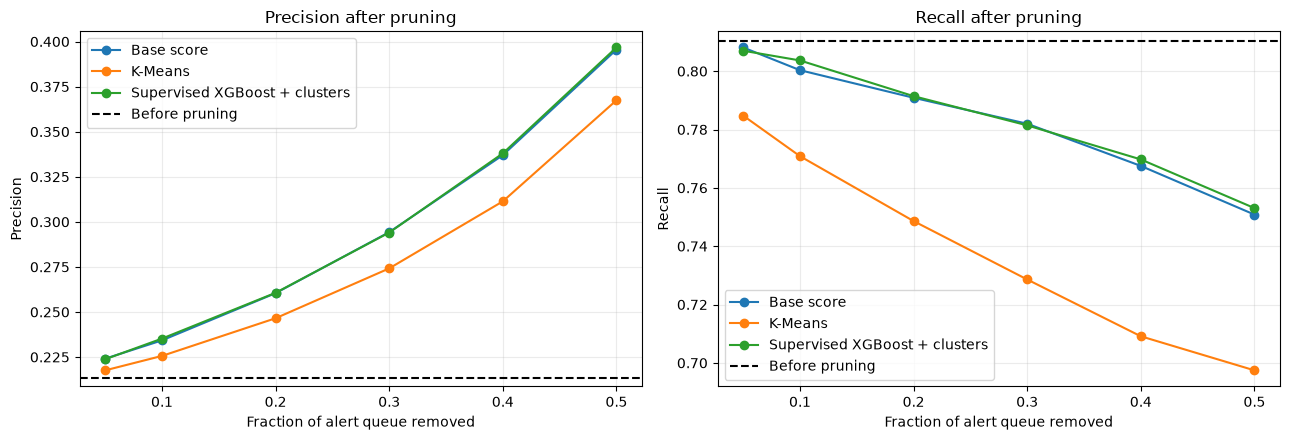

In [23]:
test_curve = comparison.query("split == 'test'")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for method, group in test_curve.groupby('method'):
    axes[0].plot(group.removal_budget, group.precision, marker='o', label=method)
    axes[1].plot(group.removal_budget, group.recall, marker='o', label=method)
axes[0].axhline(before_precision, color='black', linestyle='--', label='Before pruning')
axes[1].axhline(before_recall, color='black', linestyle='--', label='Before pruning')
for ax, title, ylabel in zip(axes, ['Precision after pruning', 'Recall after pruning'], ['Precision', 'Recall']):
    ax.set(title=title, xlabel='Fraction of alert queue removed', ylabel=ylabel)
    ax.grid(alpha=.25); ax.legend()
fig.tight_layout()
plt.show()

## 4. Diagnostics and saved experimental outputs

Feature importance is diagnostic only. The saved CSV/JSON files live under ignored `artifacts/` and are not release artifacts. Do not promote this pruning stage without institution-specific labels, a cost-approved removal budget, drift monitoring, and a policy for sending pruned alerts to lower-priority review rather than silently discarding them.

In [24]:
if supervised is not None:
    importance = pd.Series(supervised.feature_importances_, index=supervised_feature_columns).sort_values(ascending=False).head(20)
    display(importance.rename('importance').to_frame().style.format('{:.4f}'))
    importance.rename('importance').to_csv(OUTPUT_DIR / 'supervised_feature_importance.csv')
quality.to_csv(OUTPUT_DIR / 'ranking_quality.csv', index=False)
comparison.to_csv(OUTPUT_DIR / 'budget_comparison.csv', index=False)
before_after.to_csv(OUTPUT_DIR / 'before_after.csv')
k_table.to_csv(OUTPUT_DIR / 'k_selection.csv', index=False)
(OUTPUT_DIR / 'selection.json').write_text(json.dumps({
    'selected_on': 'calibration', 'method': selected_method, 'removal_budget': 0.20,
    'minimum_calibration_tp_retention': 0.95, 'production_changed': False, 'seed': SEED
}, indent=2) + '\n')
print(f'Experimental outputs saved to {OUTPUT_DIR}; production artifacts were not modified.')

,importance
cluster_1,0.5456
model_b_score,0.1238
cluster_0,0.1071
risk_score,0.0379
model_disagreement,0.0246
score_margin,0.0218
baseline_b_score,0.0071
sender_prior_incoming_count,0.0062
model_a_score,0.0057
cluster_distance_0,0.0053


Experimental outputs saved to /home/malnaser/EN_Workspace/DEVELOPMENT/_playground/DS-Internship-Summer-2026/AML_production/artifacts/fp_pruning_experiment; production artifacts were not modified.
